# <span style="color:green">Laboratorio di Simulazione Numerica </span>
## <span style="color:blue">  Tommaso Cardano Chiezzi</span>

# Esercizio 03.1 - Pricing di opzioni europee

In questo esercizio viene stimato tramite metodo Monte Carlo il prezzo al tempo $t=0$ di una **European Call option** e di una **European Put option**.

Si assume che il prezzo dell'asset segua un **Geometric Brownian Motion (GBM)**:

$$
dS(t)=rS(t)\,dt+\sigma S(t)\,dW(t),
$$

con i parametri:

$$
S(0)=100,
\qquad
T=1,
\qquad
K=100,
$$

$$
r=0.1,
\qquad
\sigma=0.25.
$$

Il prezzo delle opzioni viene stimato in due modi:

1. campionando direttamente il prezzo finale $S(T)$;
2. costruendo la traiettoria del GBM suddividendo l'intervallo $[0,T]$ in 100 intervalli temporali.

In entrambi i casi è stato utilizzato il **data blocking** per stimare il valore medio e la relativa incertezza statistica.

In particolare per entrambe le modalità sono state effettuate $M = 10^6$ campionamenti divisi in $N = 10^3$ blocchi.

I risultati Monte Carlo saranno confrontati con i valori analitici forniti dalla formula di **Black-Scholes**.

## Soluzione analitica di Black-Scholes

Per una European Call e una European Put, i prezzi analitici sono:

$$
C(S_0,0)=S_0N(d_1)-Ke^{-rT}N(d_2),
$$

$$
P(S_0,0)=Ke^{-rT}N(-d_2)-S_0N(-d_1),
$$

dove

$$
d_1=
\frac{\ln(S_0/K)+(r+\sigma^2/2)T}
{\sigma\sqrt{T}},
$$

e

$$
d_2=d_1-\sigma\sqrt{T}.
$$

Questi valori verranno utilizzati come riferimento teorico per verificare la convergenza delle simulazioni Monte Carlo.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
# Parametri del problema
S0 = 100.0
K = 100.0
T = 1.0
r = 0.1
sigma = 0.25

# Parametri di Black-Scholes
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)

# Prezzi teorici
call_theory = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
put_theory = K * np.exp(-r * T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)

print(f"Valore teorico Call = {call_theory:.6f}")
print(f"Valore teorico Put  = {put_theory:.6f}")

Valore teorico Call = 14.975791
Valore teorico Put  = 5.459533


## Caricamento dei risultati Monte Carlo

I file prodotti dal programma C++ contengono tre colonne:

1. media del singolo blocco;
2. media progressiva;
3. errore statistico progressivo.

In [6]:
# Campionamento diretto
call_direct = np.loadtxt("call_direct.txt")
put_direct = np.loadtxt("put_direct.txt")

# Campionamento della traiettoria
call_discrete = np.loadtxt("call_discrete.txt")
put_discrete = np.loadtxt("put_discrete.txt")

# Numero di blocchi
n_blocks = len(call_direct)

blocks = np.arange(1, n_blocks + 1)

print(f"Numero di blocchi caricati: {n_blocks}")

Numero di blocchi caricati: 1000


## 03.1.1 - Campionamento diretto di $S(T)$

Nel primo metodo non è necessario costruire l'intera traiettoria dell'asset.

La soluzione esatta del Geometric Brownian Motion al tempo $T$ è:

$$
S(T)=S(0)
\exp\left[
\left(r-\frac{\sigma^2}{2}\right)T
+\sigma Z\sqrt{T}
\right],
$$

dove

$$
Z\sim\mathcal{N}(0,1).
$$

Per ogni simulazione generiamo quindi una variabile normale standard $Z$ e otteniamo direttamente il prezzo finale $S(T)$.

I payoff sono:

$$
\text{Call}=\max[0,S(T)-K],
$$

$$
\text{Put}=\max[0,K-S(T)].
$$

Poiché questi payoff si riferiscono al tempo futuro $T$, vengono riportati al tempo $t=0$ mediante il fattore di sconto:

$$
e^{-rT}.
$$

Viene studiata ora la convergenza delle due stime Monte Carlo.

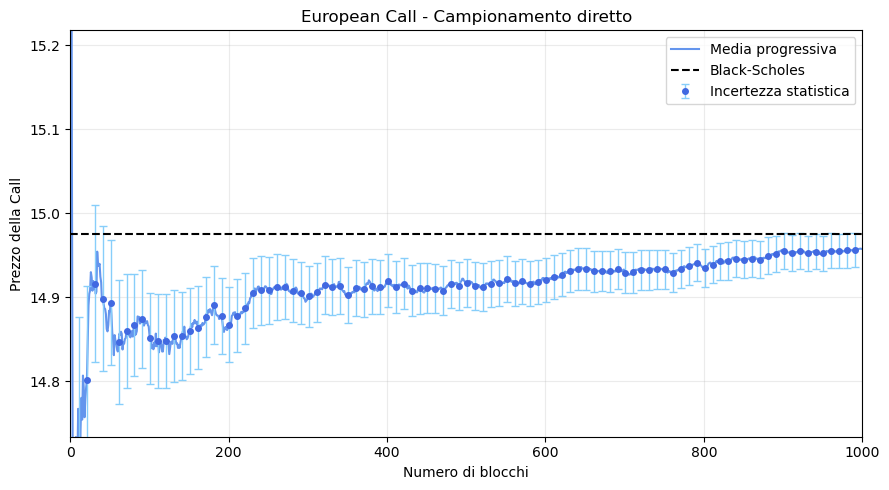

In [15]:
# CALL - CAMPIONAMENTO DIRETTO

# Una barra d'errore ogni 40 blocchi -> circa 25 barre su 1000 blocchi
idx = np.arange(0, 1000, 10)

# Intervallo verticale calcolato sulla parte stabile della simulazione
start = 100
spread = np.percentile(np.abs(call_direct_mean[start:] - call_theory), 98)
err_scale = np.percentile(call_direct_err[start:], 98)
half_range = 1.3 * (spread + err_scale)

plt.figure(figsize=(9, 5))

# Media progressiva completa
plt.plot(
    blocks,
    call_direct_mean,
    color='cornflowerblue',
    linewidth=1.5,
    label='Media progressiva'
)

# Barre d'errore solo su alcuni blocchi
plt.errorbar(
    blocks[idx],
    call_direct_mean[idx],
    yerr=call_direct_err[idx],
    fmt='o',
    markersize=4,
    capsize=3,
    elinewidth=1,
    color='royalblue',
    ecolor='lightskyblue',
    label='Incertezza statistica'
)

# Valore teorico
plt.axhline(
    call_theory,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Black-Scholes'
)

plt.xlim(0, 1000)
plt.ylim(call_theory - half_range, call_theory + half_range)

plt.xlabel("Numero di blocchi")
plt.ylabel("Prezzo della Call")
plt.title("European Call - Campionamento diretto")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

La stima progressiva del prezzo della Call oscilla inizialmente a causa del numero limitato di dati disponibili, ma tende progressivamente a stabilizzarsi.

All'aumentare del numero di blocchi, le fluttuazioni statistiche diminuiscono e il risultato Monte Carlo risulta compatibile, entro l'incertezza statistica, con il valore teorico previsto dalla formula di Black-Scholes.

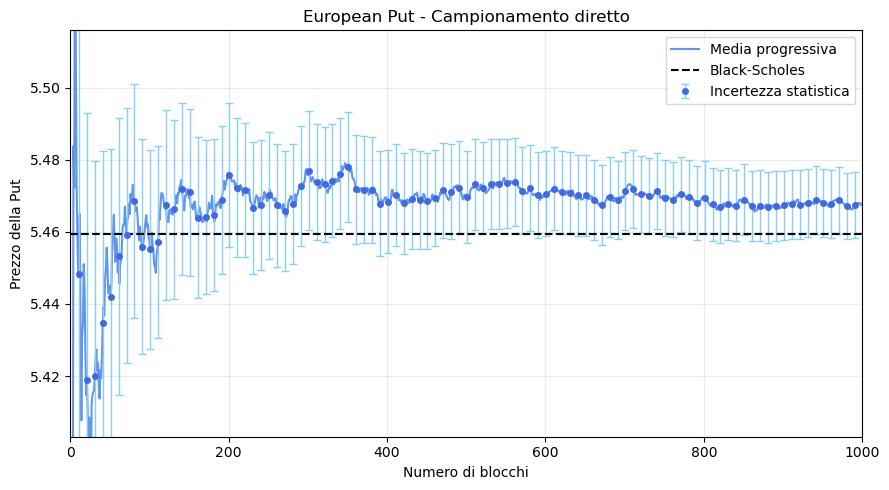

In [17]:
# PUT - CAMPIONAMENTO DIRETTO

idx = np.arange(0, 1000, 10)

start = 100
spread = np.percentile(np.abs(put_direct_mean[start:] - put_theory), 98)
err_scale = np.percentile(put_direct_err[start:], 98)
half_range = 1.3 * (spread + err_scale)

plt.figure(figsize=(9, 5))

plt.plot(
    blocks,
    put_direct_mean,
    color='cornflowerblue',
    linewidth=1.5,
    label='Media progressiva'
)

plt.errorbar(
    blocks[idx],
    put_direct_mean[idx],
    yerr=put_direct_err[idx],
    fmt='o',
    markersize=4,
    capsize=3,
    elinewidth=1,
    color='royalblue',
    ecolor='lightskyblue',
    label='Incertezza statistica'
)

plt.axhline(
    put_theory,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Black-Scholes'
)

plt.xlim(0, 1000)
plt.ylim(put_theory - half_range, put_theory + half_range)

plt.xlabel("Numero di blocchi")
plt.ylabel("Prezzo della Put")
plt.title("European Put - Campionamento diretto")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

Anche per la Put si osserva la convergenza della media progressiva verso il valore analitico.

Le barre d'errore rappresentano l'incertezza statistica sulla media ottenuta tramite il metodo del data blocking.

Il risultato finale è compatibile con la soluzione di Black-Scholes.

## 03.1.2 - Campionamento della traiettoria del GBM

Nel secondo metodo l'intervallo temporale $[0,T]$ viene diviso in

$$
N_{\mathrm{step}}=100
$$

intervalli uguali:

$$
\Delta t=\frac{T}{100}.
$$

Partendo da $S(0)$, si generano ricorsivamente:

$$
S(t_{i+1})=
S(t_i)
\exp\left[
\left(r-\frac{\sigma^2}{2}\right)\Delta t
+\sigma Z_{i+1}\sqrt{\Delta t}
\right],
$$

con

$$
Z_i\sim\mathcal{N}(0,1)
$$

indipendenti.

Dopo 100 passaggi si ottiene $S(T)$ e si calcola nuovamente i payoff della Call e della Put.



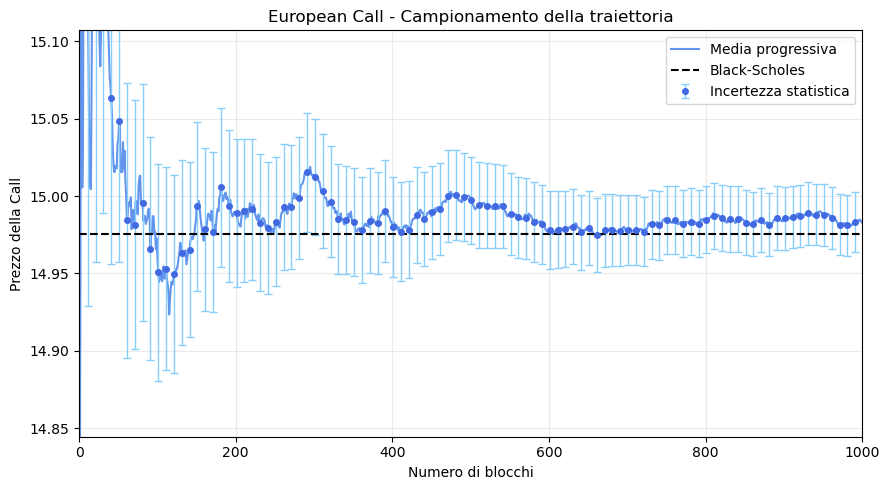

In [19]:
# CALL - CAMPIONAMENTO DELLA TRAIETTORIA

idx = np.arange(0, 1000, 10)

start = 100
spread = np.percentile(np.abs(call_discrete_mean[start:] - call_theory), 98)
err_scale = np.percentile(call_discrete_err[start:], 98)
half_range = 1.3 * (spread + err_scale)

plt.figure(figsize=(9, 5))

plt.plot(
    blocks,
    call_discrete_mean,
    color='cornflowerblue',
    linewidth=1.5,
    label='Media progressiva'
)

plt.errorbar(
    blocks[idx],
    call_discrete_mean[idx],
    yerr=call_discrete_err[idx],
    fmt='o',
    markersize=4,
    capsize=3,
    elinewidth=1,
    color='royalblue',
    ecolor='lightskyblue',
    label='Incertezza statistica'
)

plt.axhline(
    call_theory,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Black-Scholes'
)

plt.xlim(0, 1000)
plt.ylim(call_theory - half_range, call_theory + half_range)

plt.xlabel("Numero di blocchi")
plt.ylabel("Prezzo della Call")
plt.title("European Call - Campionamento della traiettoria")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

Anche costruendo esplicitamente la traiettoria del Geometric Brownian Motion, la stima della Call converge verso il valore analitico.

Poiché ad ogni intervallo temporale viene utilizzata la soluzione esatta del GBM, ci si aspetta che questo metodo e il campionamento diretto forniscano risultati statisticamente compatibili.

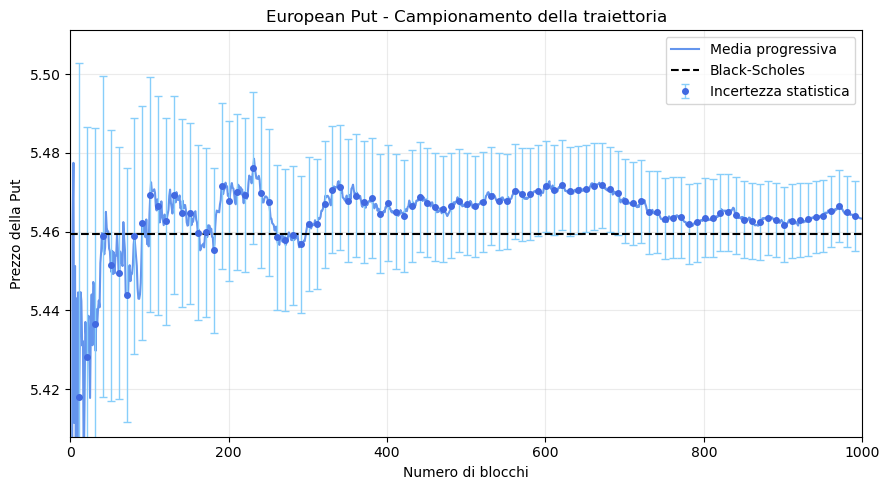

In [21]:
# PUT - CAMPIONAMENTO DELLA TRAIETTORIA

idx = np.arange(0, 1000, 10)

start = 100
spread = np.percentile(np.abs(put_discrete_mean[start:] - put_theory), 98)
err_scale = np.percentile(put_discrete_err[start:], 98)
half_range = 1.3 * (spread + err_scale)

plt.figure(figsize=(9, 5))

plt.plot(
    blocks,
    put_discrete_mean,
    color='cornflowerblue',
    linewidth=1.5,
    label='Media progressiva'
)

plt.errorbar(
    blocks[idx],
    put_discrete_mean[idx],
    yerr=put_discrete_err[idx],
    fmt='o',
    markersize=4,
    capsize=3,
    elinewidth=1,
    color='royalblue',
    ecolor='lightskyblue',
    label='Incertezza statistica'
)

plt.axhline(
    put_theory,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Black-Scholes'
)

plt.xlim(0, 1000)
plt.ylim(put_theory - half_range, put_theory + half_range)

plt.xlabel("Numero di blocchi")
plt.ylabel("Prezzo della Put")
plt.title("European Put - Campionamento della traiettoria")

plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

La stima della Put mostra lo stesso comportamento: aumentando il numero di blocchi la media progressiva tende a stabilizzarsi e risulta compatibile con il valore teorico di Black-Scholes.

I due differenti metodi di campionamento forniscono quindi risultati consistenti.

## Confronto tra campionamento diretto e campionamento della traiettoria

Vengono confrontati ora direttamente le medie progressive ottenute con i due metodi.

Poiché sia il campionamento diretto sia il campionamento sui 100 intervalli utilizzano la soluzione esatta del Geometric Brownian Motion, non ci si aspetta una differenza sistematica tra le due stime.

Le eventuali differenze osservate sono dovute esclusivamente alle fluttuazioni statistiche della simulazione Monte Carlo.

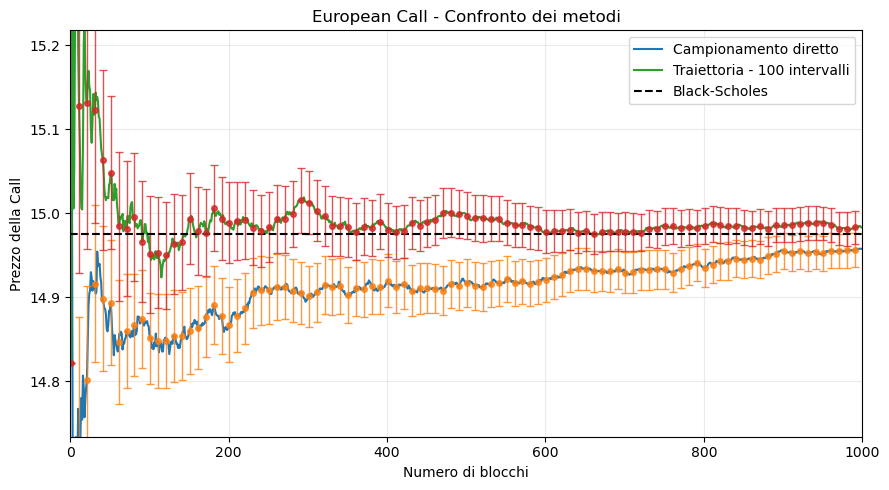

In [31]:
# CONFRONTO CALL - CAMPIONAMENTO DIRETTO VS TRAIETTORIA

# Mostriamo una barra d'errore ogni 10 blocchi
idx = np.arange(0, 1000, 10)

# Intervallo verticale calcolato sulla parte stabile delle due simulazioni
start = 100

spread_direct = np.percentile(
    np.abs(call_direct_mean[start:] - call_theory), 98
)

spread_discrete = np.percentile(
    np.abs(call_discrete_mean[start:] - call_theory), 98
)

error_direct = np.percentile(
    call_direct_err[start:], 98
)

error_discrete = np.percentile(
    call_discrete_err[start:], 98
)

half_range = 1.3 * max(
    spread_direct + error_direct,
    spread_discrete + error_discrete
)


plt.figure(figsize=(9, 5))


# Media progressiva - campionamento diretto
plt.plot(
    blocks,
    call_direct_mean,
    linewidth=1.5,
    label='Campionamento diretto'
)


# Barre d'errore - campionamento diretto
plt.errorbar(
    blocks[idx],
    call_direct_mean[idx],
    yerr=call_direct_err[idx],
    fmt='o',
    markersize=4,
    capsize=3,
    elinewidth=1,
    alpha=0.8
)


# Media progressiva - campionamento della traiettoria
plt.plot(
    blocks,
    call_discrete_mean,
    linewidth=1.5,
    label='Traiettoria - 100 intervalli'
)


# Barre d'errore - campionamento della traiettoria
plt.errorbar(
    blocks[idx],
    call_discrete_mean[idx],
    yerr=call_discrete_err[idx],
    fmt='o',
    markersize=4,
    capsize=3,
    elinewidth=1,
    alpha=0.8
)


# Valore teorico di Black-Scholes
plt.axhline(
    call_theory,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Black-Scholes'
)


plt.xlim(0, 1000)
plt.ylim(
    call_theory - half_range,
    call_theory + half_range
)

plt.xlabel("Numero di blocchi")
plt.ylabel("Prezzo della Call")
plt.title("European Call - Confronto dei metodi")

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

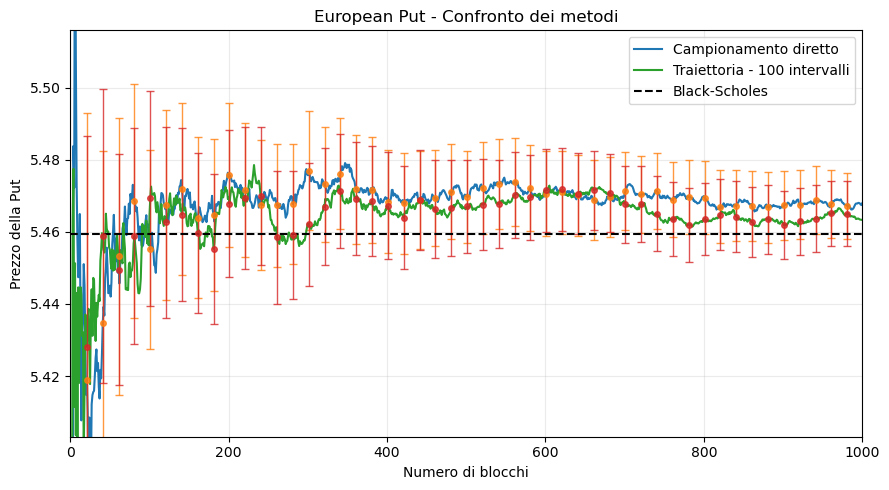

In [30]:
# CONFRONTO PUT - CAMPIONAMENTO DIRETTO VS TRAIETTORIA

# Mostriamo una barra d'errore ogni 40 blocchi
idx = np.arange(0, 1000, 20)

# Intervallo verticale calcolato sulla parte stabile delle due simulazioni
start = 100

spread_direct = np.percentile(
    np.abs(put_direct_mean[start:] - put_theory), 98
)

spread_discrete = np.percentile(
    np.abs(put_discrete_mean[start:] - put_theory), 98
)

error_direct = np.percentile(
    put_direct_err[start:], 98
)

error_discrete = np.percentile(
    put_discrete_err[start:], 98
)

half_range = 1.3 * max(
    spread_direct + error_direct,
    spread_discrete + error_discrete
)


plt.figure(figsize=(9, 5))


# Media progressiva - campionamento diretto
plt.plot(
    blocks,
    put_direct_mean,
    linewidth=1.5,
    label='Campionamento diretto'
)


# Barre d'errore - campionamento diretto
plt.errorbar(
    blocks[idx],
    put_direct_mean[idx],
    yerr=put_direct_err[idx],
    fmt='o',
    markersize=4,
    capsize=3,
    elinewidth=1,
    alpha=0.8
)


# Media progressiva - campionamento della traiettoria
plt.plot(
    blocks,
    put_discrete_mean,
    linewidth=1.5,
    label='Traiettoria - 100 intervalli'
)


# Barre d'errore - campionamento della traiettoria
plt.errorbar(
    blocks[idx],
    put_discrete_mean[idx],
    yerr=put_discrete_err[idx],
    fmt='o',
    markersize=4,
    capsize=3,
    elinewidth=1,
    alpha=0.8
)


# Valore teorico di Black-Scholes
plt.axhline(
    put_theory,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Black-Scholes'
)


plt.xlim(0, 1000)
plt.ylim(
    put_theory - half_range,
    put_theory + half_range
)

plt.xlabel("Numero di blocchi")
plt.ylabel("Prezzo della Put")
plt.title("European Put - Confronto dei metodi")

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

In [27]:
print("CALL")
print("--------------------------------------------------")
print(
    f"Campionamento diretto     = "
    f"{call_direct_mean[-1]:.6f} ± {call_direct_err[-1]:.6f}"
)
print(
    f"Traiettoria (100 step)    = "
    f"{call_discrete_mean[-1]:.6f} ± {call_discrete_err[-1]:.6f}"
)
print(
    f"Black-Scholes             = "
    f"{call_theory:.6f}"
)

print()

print("PUT")
print("--------------------------------------------------")
print(
    f"Campionamento diretto     = "
    f"{put_direct_mean[-1]:.6f} ± {put_direct_err[-1]:.6f}"
)
print(
    f"Traiettoria (100 step)    = "
    f"{put_discrete_mean[-1]:.6f} ± {put_discrete_err[-1]:.6f}"
)
print(
    f"Black-Scholes             = "
    f"{put_theory:.6f}"
)

CALL
--------------------------------------------------
Campionamento diretto     = 14.957306 ± 0.020188
Traiettoria (100 step)    = 14.982790 ± 0.019498
Black-Scholes             = 14.975791

PUT
--------------------------------------------------
Campionamento diretto     = 5.467928 ± 0.009145
Traiettoria (100 step)    = 5.463298 ± 0.008874
Black-Scholes             = 5.459533


## Conclusioni

E' stato stimato tramite simulazione Monte Carlo il prezzo di una European Call e di una European Put utilizzando due procedure differenti.

Nel primo caso è stato campionato direttamente il prezzo finale $S(T)$ dalla soluzione esatta del Geometric Brownian Motion.

Nel secondo caso è stato costruito esplicitamente la traiettoria dell'asset suddividendo l'intervallo $[0,T]$ in 100 intervalli temporali e applicando ad ogni passo la transizione esatta del GBM.

In entrambi i casi le stime sono risultate compatibili, entro l'incertezza statistica, con i valori analitici ottenuti tramite la formula di Black-Scholes.

Il confronto mostra inoltre che i due metodi di campionamento forniscono risultati statisticamente equivalenti, come previsto, mentre il data blocking permette di osservare la progressiva stabilizzazione delle stime e di associarvi un'incertezza statistica.